In [ ]:
# ============================================================
# PROJECT: STUDENT PERFORMANCE PREDICTION USING MACHINE LEARNING
# Models: Logistic Regression, Gaussian Naive Bayes, SVM
# Platform: Google Colab
# Dataset: UCI Student Performance - Mathematics
# ============================================================

import os
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance

import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

# Download the official UCI dataset archive
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
zip_path = "/content/student_performance.zip"
extract_dir = "/content/student_performance"

os.makedirs(extract_dir, exist_ok=True)

if not os.path.exists(os.path.join(extract_dir, "student-mat.csv")):
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(extract_dir)

print("Libraries imported successfully.")
print("Dataset downloaded and extracted.")

Libraries imported successfully.
Dataset downloaded and extracted.


In [ ]:
import os

print("Checking dataset extraction directory...")

extract_dir = "/content/student_performance"

if os.path.exists(extract_dir):
    for root, dirs, files_in_dir in os.walk(extract_dir):
        print("\nFolder:", root)
        for filename in files_in_dir:
            print("  ", filename)
else:
    print("Extraction directory does not exist!")

Checking dataset extraction directory...

Folder: /content/student_performance
   student.zip
   .student.zip_old


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving student-mat[1].xlsx to student-mat[1].xlsx


In [ ]:
import pandas as pd

# Reload the original uploaded file
raw_df = pd.read_excel("student-mat[1].xlsx", header=None)

# Extract the semicolon-separated text
first_row = raw_df.iloc[0, 0]

# Determine whether the first row contains the column headers
if ";" in str(first_row):
    split_df = raw_df.iloc[:, 0].astype(str).str.split(";", expand=True)

    # Use the first row as column headers
    split_df.columns = (
        split_df.iloc[0]
        .str.replace('"', '', regex=False)
        .str.strip()
    )

    df = split_df.iloc[1:].reset_index(drop=True)

else:
    raise ValueError(
        "The file format is different than expected. "
        "Please share the output of raw_df.head()."
    )

# Clean column names
df.columns = (
    df.columns.astype(str)
    .str.replace('"', '', regex=False)
    .str.strip()
)

# Remove quotation marks and whitespace from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.replace('"', '', regex=False).str.strip()

# Convert columns to numeric wherever all non-empty values are numeric
for col in df.columns:
    converted = pd.to_numeric(df[col], errors="coerce")
    if converted.notna().sum() == df[col].notna().sum():
        df[col] = converted

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nFinal grade distribution:")
display(df["G3"].value_counts().sort_index().to_frame("Student Count"))

Dataset loaded successfully!
Dataset shape: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

First five rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Final grade distribution:


,Student Count
G3,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47


In [ ]:
# Check dataset information
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Create the target performance categories
def categorize_performance(score):
    if score <= 9:
        return "Low"
    elif score <= 14:
        return "Medium"
    else:
        return "High"

df["Performance"] = df["G3"].apply(categorize_performance)

print("\nStudent Performance Category Counts:")
display(df["Performance"].value_counts().to_frame("Number of Students"))

Dataset shape: (395, 33)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nur

,Number of Students
Performance,
Medium,192
Low,130
High,73


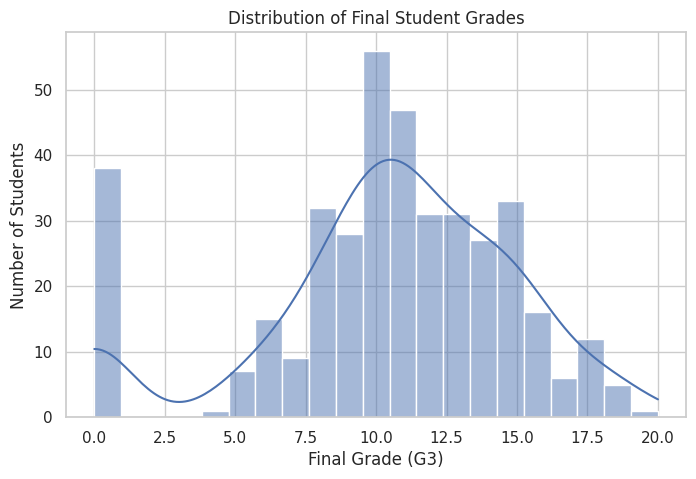

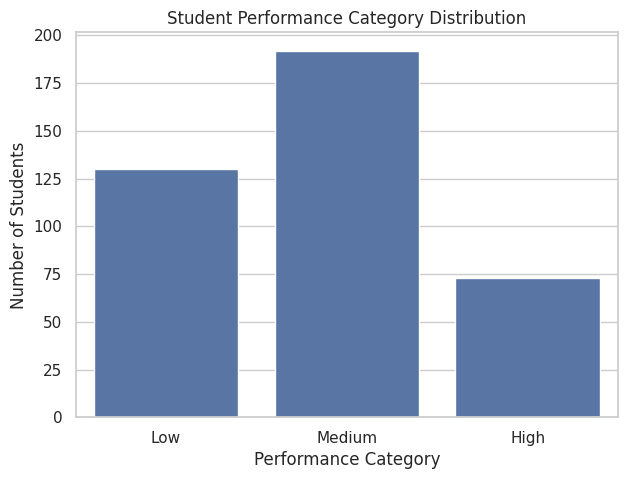

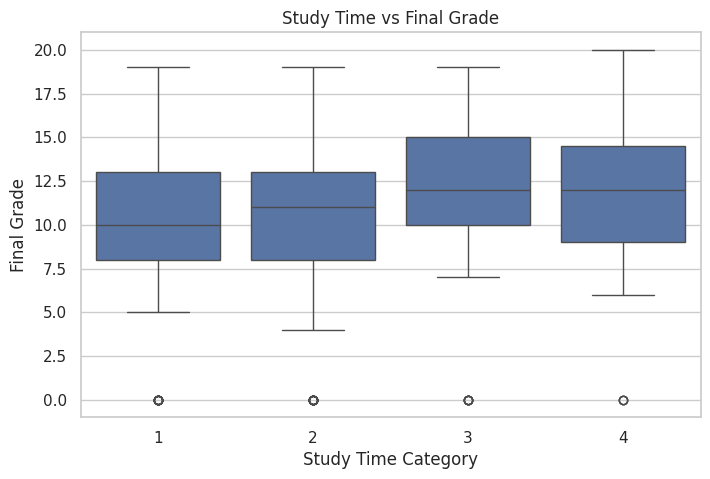

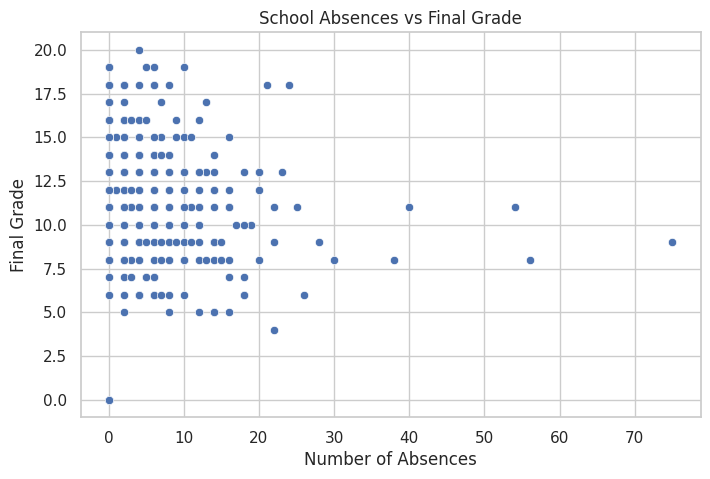

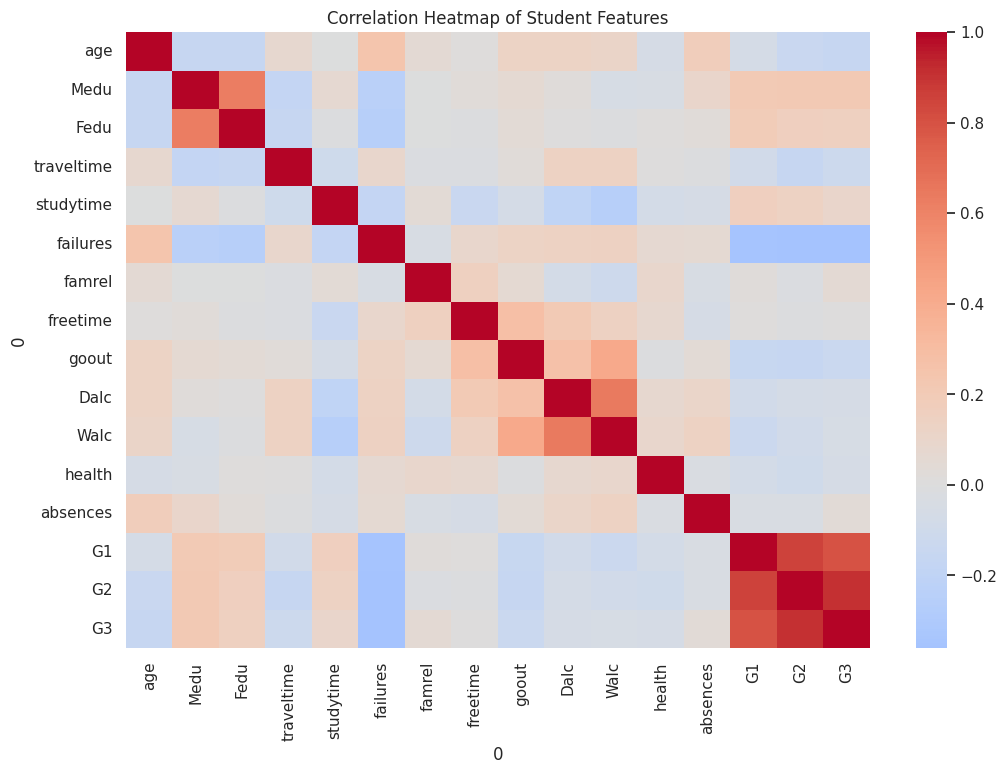

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Graph 1: Distribution of final grades
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=21, kde=True)
plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()

# Graph 2: Performance category distribution
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="Performance",
    order=["Low", "Medium", "High"]
)
plt.title("Student Performance Category Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.show()

# Graph 3: Study time vs final grades
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade")
plt.show()

# Graph 4: Absences vs final grades
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="absences", y="G3")
plt.title("School Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")
plt.show()

# Graph 5: Correlation heatmap
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of Student Features")
plt.show()

In [ ]:
# STEP 4: DATA PREPARATION

from sklearn.model_selection import train_test_split

# Create the target categories if not already present
def categorize_performance(score):
    if score <= 9:
        return "Low"
    elif score <= 14:
        return "Medium"
    else:
        return "High"

df["Performance"] = df["G3"].apply(categorize_performance)

# Separate input features and target
columns_to_remove = ["G1", "G2", "G3", "Performance"]

X = df.drop(columns=columns_to_remove)
y = df["Performance"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget category counts:")
display(y.value_counts().to_frame("Number of Students"))

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining category distribution:")
display(y_train.value_counts().to_frame("Training Count"))

print("\nTesting category distribution:")
display(y_test.value_counts().to_frame("Testing Count"))

Input features shape: (395, 30)
Target shape: (395,)

Target category counts:


,Number of Students
Performance,
Medium,192
Low,130
High,73



Training samples: 316
Testing samples: 79

Training category distribution:


,Training Count
Performance,
Medium,154
Low,104
High,58



Testing category distribution:


,Testing Count
Performance,
Medium,38
Low,26
High,15


In [ ]:
# STEP 5A: PREPROCESSING PIPELINE

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

# Process numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully!")

Number of numerical features: 13
Number of categorical features: 17

Preprocessing pipeline created successfully!


In [ ]:
# STEP 5B: MODEL TRAINING

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        kernel="rbf",
        C=1.0,
        random_state=42
    )
}

trained_models = {}

for model_name, classifier in models.items():

    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model_pipeline.fit(X_train, y_train)

    trained_models[model_name] = model_pipeline

    print(f"{model_name}: Training completed successfully!")

print("\nAll three models have been trained.")

Logistic Regression: Training completed successfully!
Gaussian Naive Bayes: Training completed successfully!
Support Vector Machine: Training completed successfully!

All three models have been trained.


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Logistic Regression,0.5316,0.5041,0.4843,0.4886
1,Gaussian Naive Bayes,0.2658,0.3741,0.3740,0.2647
2,Support Vector Machine,0.4937,0.4975,0.3852,0.3581


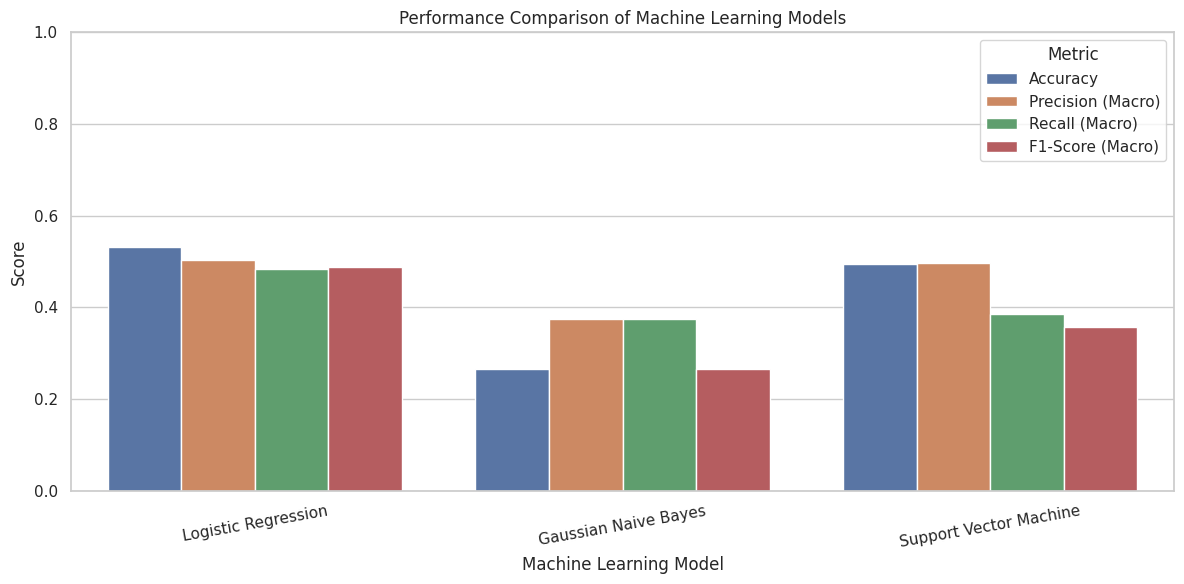

In [ ]:
# STEP 6: MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results = []
predictions = {}

for model_name, model in trained_models.items():

    # Predict on unseen test data
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

# Visual comparison
plot_df = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score",
    value_vars=[
        "Accuracy",
        "Precision (Macro)",
        "Recall (Macro)",
        "F1-Score (Macro)"
    ]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


MODEL: Logistic Regression

Classification Report:

              precision    recall  f1-score   support

         Low       0.63      0.46      0.53        26
      Medium       0.57      0.66      0.61        38
        High       0.31      0.33      0.32        15

    accuracy                           0.53        79
   macro avg       0.50      0.48      0.49        79
weighted avg       0.54      0.53      0.53        79



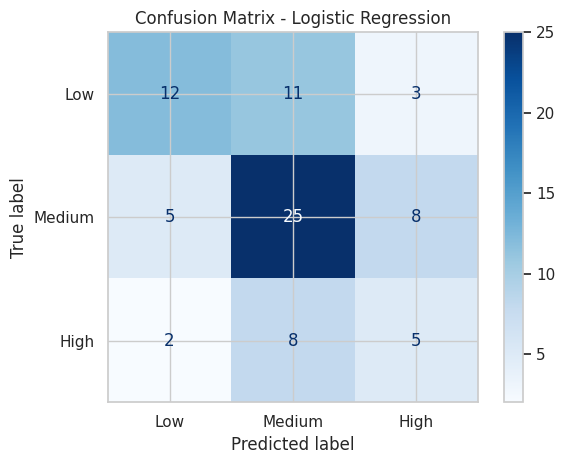


MODEL: Gaussian Naive Bayes

Classification Report:

              precision    recall  f1-score   support

         Low       0.70      0.27      0.39        26
      Medium       0.22      0.05      0.09        38
        High       0.20      0.80      0.32        15

    accuracy                           0.27        79
   macro avg       0.37      0.37      0.26        79
weighted avg       0.38      0.27      0.23        79



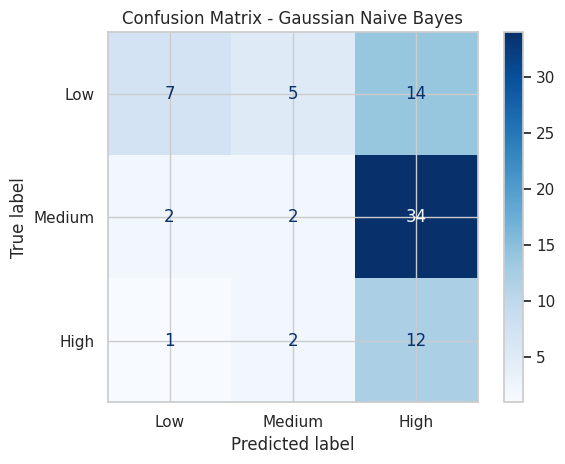


MODEL: Support Vector Machine

Classification Report:

              precision    recall  f1-score   support

         Low       0.50      0.15      0.24        26
      Medium       0.49      0.87      0.63        38
        High       0.50      0.13      0.21        15

    accuracy                           0.49        79
   macro avg       0.50      0.39      0.36        79
weighted avg       0.50      0.49      0.42        79



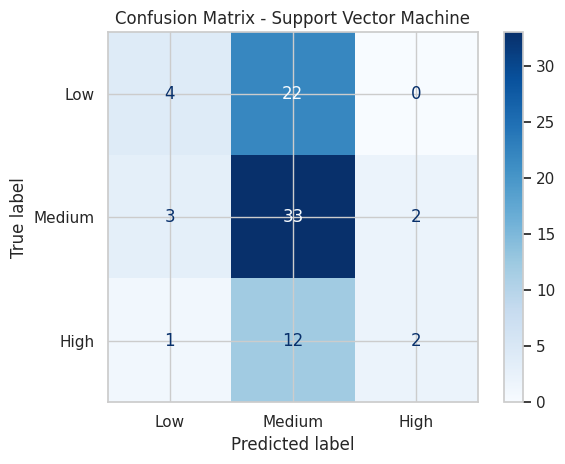

In [ ]:
# STEP 7: DETAILED MODEL EVALUATION

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = ["Low", "Medium", "High"]

for model_name, y_pred in predictions.items():

    print("\n" + "=" * 55)
    print("MODEL:", model_name)
    print("=" * 55)

    # Precision, recall and F1-score for each category
    print("\nClassification Report:\n")

    print(classification_report(
        y_test,
        y_pred,
        labels=class_names,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_names
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

STRATIFIED 5-FOLD CROSS-VALIDATION RESULTS


,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,Macro F1 Std
0,Logistic Regression,0.4839,0.0722,0.4564,0.0741
1,Support Vector Machine,0.5505,0.0207,0.3890,0.0461
2,Gaussian Naive Bayes,0.3004,0.0498,0.2883,0.0535


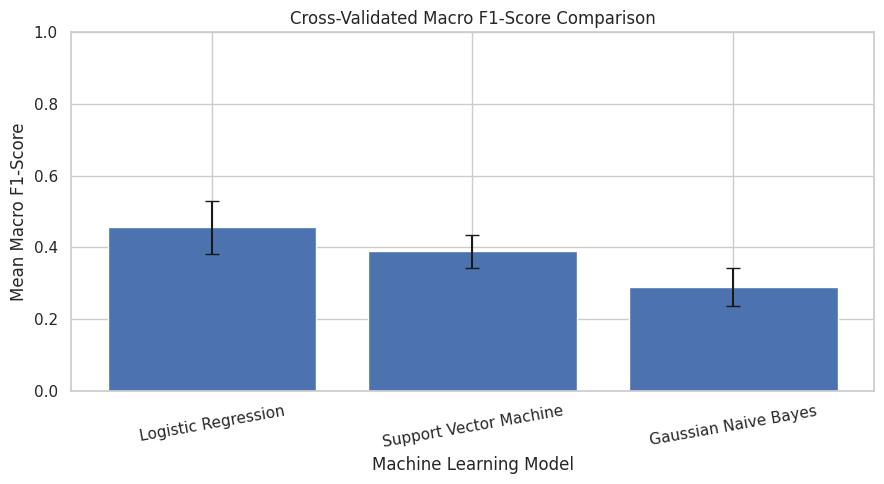

In [ ]:
# STEP 8: STRATIFIED 5-FOLD CROSS-VALIDATION

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for model_name, classifier in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean Macro F1": scores["test_f1_macro"].mean(),
        "Macro F1 Std": scores["test_f1_macro"].std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    by="Mean Macro F1",
    ascending=False
).reset_index(drop=True)

print("STRATIFIED 5-FOLD CROSS-VALIDATION RESULTS")
display(cv_df.round(4))

# Plot mean cross-validation macro F1
plt.figure(figsize=(9, 5))

plt.bar(
    cv_df["Model"],
    cv_df["Mean Macro F1"],
    yerr=cv_df["Macro F1 Std"],
    capsize=5
)

plt.title("Cross-Validated Macro F1-Score Comparison")
plt.ylabel("Mean Macro F1-Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

Best model based on cross-validation Macro F1:
Logistic Regression

Top 15 features by permutation importance:


,Feature,Importance Mean,Importance Std
14,failures,0.0885,0.0283
9,Fjob,0.0789,0.0300
8,Mjob,0.0782,0.0289
25,goout,0.0697,0.0187
2,age,0.0419,0.0147
6,Medu,0.0404,0.0212
26,Dalc,0.0381,0.0207
15,schoolsup,0.0374,0.0222
27,Walc,0.0281,0.0148
10,reason,0.0276,0.0166


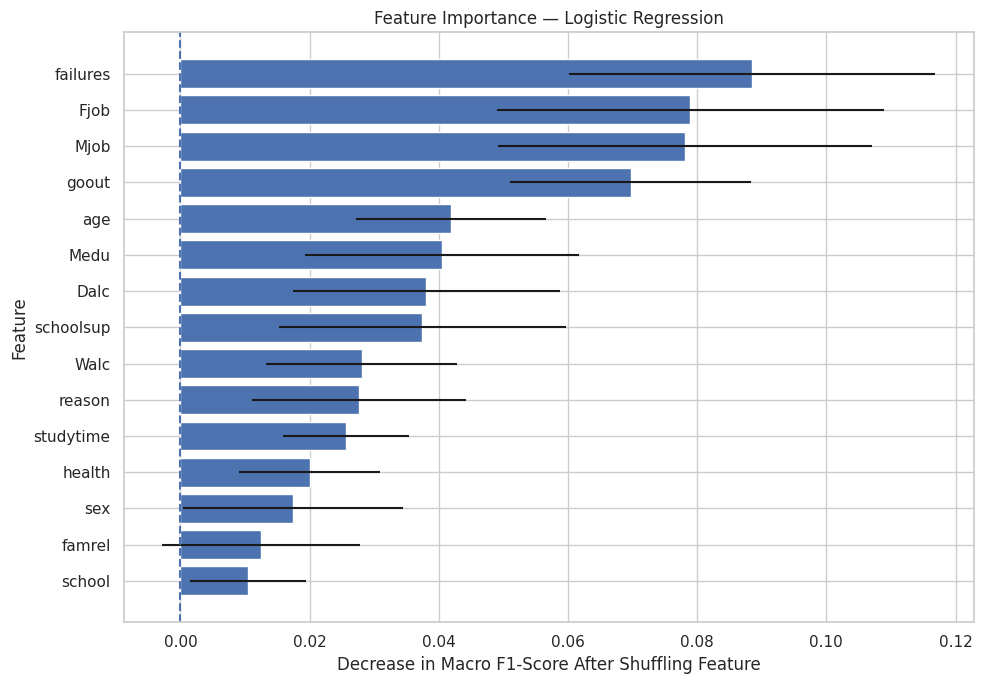

In [ ]:
# STEP 9: FEATURE IMPORTANCE ANALYSIS

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select the model with the highest cross-validation Macro F1
best_model_name = cv_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on cross-validation Macro F1:")
print(best_model_name)

# Calculate permutation importance on the held-out test set
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": importance_result.importances_mean,
    "Importance Std": importance_result.importances_std
}).sort_values(
    by="Importance Mean",
    ascending=False
)

print("\nTop 15 features by permutation importance:")
display(importance_df.head(15).round(4))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance Mean"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"]
)

plt.axvline(0, linestyle="--")
plt.title(f"Feature Importance — {best_model_name}")
plt.xlabel("Decrease in Macro F1-Score After Shuffling Feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
# STEP 11: DEMONSTRATE A SAMPLE PREDICTION

sample_student = X_test.iloc[[0]]

actual = y_test.iloc[0]
predicted = best_model.predict(sample_student)[0]

print("=" * 45)
print("STUDENT PERFORMANCE PREDICTION")
print("=" * 45)

print("Selected model:", best_model_name)
print("Actual category:", actual)
print("Predicted category:", predicted)

if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(sample_student)[0]

    print("\nEstimated class probabilities:")
    for category, probability in zip(
        best_model.classes_, probabilities
    ):
        print(f"{category}: {probability:.2%}")

STUDENT PERFORMANCE PREDICTION
Selected model: Logistic Regression
Actual category: Low
Predicted category: Medium

Estimated class probabilities:
High: 13.35%
Low: 18.45%
Medium: 68.20%


In [ ]:
# STEP 10: SAVE PROJECT OUTPUTS

import os
import joblib
import shutil
import pandas as pd
from google.colab import files

output_dir = "/content/student_performance_outputs"
os.makedirs(output_dir, exist_ok=True)

# Save evaluation results
results_df.to_csv(
    f"{output_dir}/test_set_model_comparison.csv",
    index=False
)

cv_df.to_csv(
    f"{output_dir}/cross_validation_results.csv",
    index=False
)

importance_df.to_csv(
    f"{output_dir}/feature_importance.csv",
    index=False
)

# Save actual and predicted categories
prediction_df = pd.DataFrame({
    "Actual": y_test
})

for model_name, y_pred in predictions.items():
    prediction_df[model_name] = y_pred

prediction_df.to_csv(
    f"{output_dir}/test_set_predictions.csv"
)

# Save all trained models
joblib.dump(
    trained_models,
    f"{output_dir}/all_trained_models.joblib"
)

# Save the selected model
joblib.dump(
    best_model,
    f"{output_dir}/best_model.joblib"
)

# Save the dataset with the target category
df.to_csv(
    f"{output_dir}/student_performance_dataset.csv",
    index=False
)

# Save a summary of the experimental setup
with open(f"{output_dir}/project_summary.txt", "w") as file:
    file.write("Student Performance Prediction Using Machine Learning\n")
    file.write(f"Dataset shape: {df.shape}\n")
    file.write(f"Training samples: {len(X_train)}\n")
    file.write(f"Testing samples: {len(X_test)}\n")
    file.write(f"Selected model by CV macro F1: {best_model_name}\n")

# Create ZIP file
zip_path = shutil.make_archive(
    "/content/student_performance_project",
    "zip",
    output_dir
)

print("All project outputs saved successfully!")
print("Files included:")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

files.download(zip_path)

All project outputs saved successfully!
Files included:
- all_trained_models.joblib
- best_model.joblib
- cross_validation_results.csv
- feature_importance.csv
- project_summary.txt
- student_performance_dataset.csv
- test_set_model_comparison.csv
- test_set_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>